In [3]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42

In [4]:
df = pd.read_csv("IMDB Dataset.csv")
print(df.shape)
df.head()

(50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [5]:
print(df["sentiment"].value_counts())
print("duplicates:", df.duplicated().sum())

df["n_words"] = df["review"].str.split().str.len()
df["n_words"].describe()

sentiment
positive    25000
negative    25000
Name: count, dtype: int64
duplicates: 418


count    50000.000000
mean       231.156940
std        171.343997
min          4.000000
25%        126.000000
50%        173.000000
75%        280.000000
max       2470.000000
Name: n_words, dtype: float64

In [6]:
# one raw review, to see what we are dealing with
print(df["review"][1])

A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only "has got all the polari" but he has all the voices down pat too! You can truly see the seamless editing guided by the references to Williams' diary entries, not only is it well worth the watching but it is a terrificly written and performed piece. A masterful production about one of the great master's of comedy and his life. <br /><br />The realism really comes home with the little things: the fantasy of the guard which, rather than use the traditional 'dream' techniques remains solid then disappears. It plays on our knowledge and our senses, particularly with the scenes concerning Orton and Halliwell and the sets (particularly of their flat with Halliwell's murals decorating every surface) are terribly well done.


The raw text has `<br />` html tags in it, mixed case and punctuation, so some cleaning is needed. Duplicates are also there, so I drop them before splitting (otherwise the same review could be in both train and test).

In [7]:
df = df.drop_duplicates(subset="review").reset_index(drop=True)
df["label"] = (df["sentiment"] == "positive").astype(int)
len(df)

49582

## Text preprocessing, step by step

Doing it manually on one review first so I know what the vectorizer is doing internally.

In [8]:
sample = df["review"][1]

def clean(text):
    text = text.lower()
    text = re.sub(r"<[^>]+>", " ", text)       # html tags
    text = re.sub(r"[^a-z\s']", " ", text)     # keep letters and apostrophes
    return re.sub(r"\s+", " ", text).strip()

cleaned = clean(sample)
tokens = cleaned.split()                         # tokenization (simple whitespace after cleaning)
print(len(tokens), "tokens:", tokens[:15])

158 tokens: ['a', 'wonderful', 'little', 'production', 'the', 'filming', 'technique', 'is', 'very', 'unassuming', 'very', 'old', 'time', 'bbc', 'fashion']


In [9]:
# stopwords. sklearn's list also contains negations (not, no, never...) which matter a lot
# for sentiment ("not good" vs "good"), so I take those out of the stoplist.
negations = {"not", "no", "nor", "never", "cannot", "nothing", "nobody", "none", "neither"}
stop_words = sorted(ENGLISH_STOP_WORDS - negations)

no_stop = [t for t in tokens if t not in stop_words]
print(len(tokens), "->", len(no_stop), "tokens after stopword removal")
print(no_stop[:15])

158 -> 79 tokens after stopword removal
['wonderful', 'little', 'production', 'filming', 'technique', 'unassuming', 'old', 'time', 'bbc', 'fashion', 'gives', 'comforting', 'discomforting', 'sense', 'realism']


## TF-IDF

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    df["review"], df["label"], test_size=0.2, stratify=df["label"], random_state=RANDOM_STATE
)
print(len(X_train), len(X_test))

tfidf = TfidfVectorizer(
    preprocessor=clean,
    stop_words=stop_words,
    ngram_range=(1, 2),
    min_df=5,
    max_features=50000,
    sublinear_tf=True,
)
Xt = tfidf.fit_transform(X_train)
print("matrix:", Xt.shape, "| non-zero share:", round(Xt.nnz / np.prod(Xt.shape), 4))

39665 9917
matrix: (39665, 50000) | non-zero share: 0.0021


## Models

In [11]:
def make_pipe(clf):
    return Pipeline([
        ("tfidf", TfidfVectorizer(preprocessor=clean, stop_words=stop_words, ngram_range=(1, 2),
                                  min_df=5, max_features=50000, sublinear_tf=True)),
        ("clf", clf),
    ])

models = {
    "Logistic Regression": make_pipe(LogisticRegression(max_iter=1000, C=5)),
    "Multinomial NB": make_pipe(MultinomialNB(alpha=0.5)),
}

results = {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    results[name] = accuracy_score(y_test, pred)
    print(f"{name:20s} test accuracy = {results[name]:.4f}")

Logistic Regression  test accuracy = 0.9066
Multinomial NB       test accuracy = 0.8849


best: Logistic Regression
              precision    recall  f1-score   support

    negative      0.911     0.901     0.906      4940
    positive      0.903     0.912     0.907      4977

    accuracy                          0.907      9917
   macro avg      0.907     0.907     0.907      9917
weighted avg      0.907     0.907     0.907      9917



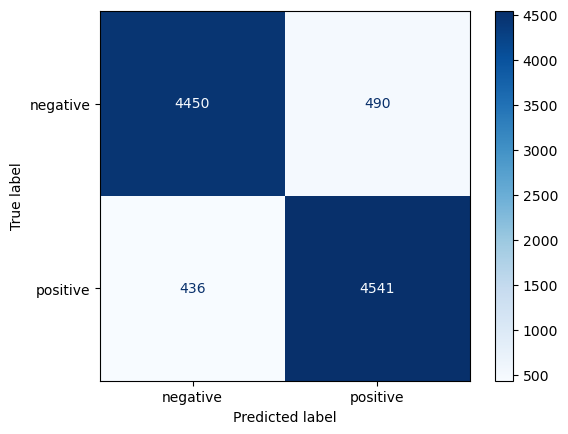

In [12]:
best_name = max(results, key=results.get)
best = models[best_name]
pred = best.predict(X_test)

print("best:", best_name)
print(classification_report(y_test, pred, target_names=["negative", "positive"], digits=3))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["negative", "positive"]).plot(cmap="Blues")
plt.show()

## What did the model learn?

In [13]:
# only for logistic regression: coefficients map directly to words
lr = models["Logistic Regression"]
vocab = np.array(lr.named_steps["tfidf"].get_feature_names_out())
coef = lr.named_steps["clf"].coef_[0]
order = np.argsort(coef)

print("most negative:", list(vocab[order[:15]]))
print("most positive:", list(vocab[order[-15:]][::-1]))

most negative: ['worst', 'awful', 'waste', 'boring', 'bad', 'terrible', 'poor', 'disappointment', 'dull', 'fails', 'horrible', 'poorly', 'disappointing', 'not worth', 'lame']
most positive: ['great', 'excellent', 'perfect', 'amazing', 'best', 'wonderful', 'hilarious', 'superb', 'brilliant', 'enjoyable', 'today', 'favorite', 'funniest', 'loved', 'gem']


In [14]:
# look at some mistakes
wrong = X_test[pred != y_test]
for r, t in list(zip(wrong.head(3), y_test[pred != y_test].head(3))):
    print("true:", "positive" if t else "negative")
    print(r[:350].replace("<br />", " "), "...\n")

true: positive
This isn't exactly a great film, but I admire the writers and director for trying something a little different. The film's main theme is fate and small, seemingly insignificant things that can greatly change the future. In some ways this reminds me of the film SLIDING DOORS, though instead of focusing on one random event, seemingly random stuff hap ...

true: negative
Despite being a huge fan of Fred Astaire and Ginger Rogers' movies, it wasn't until about 6 years ago that I first saw 'Follow the Fleet'. I knew all the songs from an old Astaire/Rogers record (yes, vinyl) but knew nothing of the plot.  Unfortunately, while the songs are catchy and Ginger Rogers' character is sweet and funny, you just ca ...

true: positive
Well, well....Roeg touched a bit of a nerve there, didn't he? He was a genius while he was cataloguing his various characters' descents into psychosis for a couple of decades, but as soon as he has the bad taste to suggest that redemption (or even some 

In [15]:
# try it on new text
tests = [
    "Absolutely loved this movie, the acting was brilliant",
    "Boring plot and terrible acting, a complete waste of time",
    "It was not good at all",
    "Not bad, actually pretty enjoyable",
]
for t, p in zip(tests, best.predict(tests)):
    print("positive" if p else "negative", "|", t)

positive | Absolutely loved this movie, the acting was brilliant
negative | Boring plot and terrible acting, a complete waste of time
negative | It was not good at all
positive | Not bad, actually pretty enjoyable
